# Condensation Tutorial: Radius Bin

This example constructs native binned data and evaluates the initial
condensation rate. For a time-evolving particle-resolved example, see
`staggered_condensation_example.ipynb`.

Condensation is the first process where this framework we have been building
up is applied. Here we need to account for the gas phase and the particle
phase, then ensure that the partial pressures of species at the surface of
the particle are equal to the partial pressure in the gas.

**Core Concepts:**

- **Runnable**: An abstract base class defining the interface for aerosol
  transformation processes. An aerosol object is passed to the process, and
  the process is expected to modify the aerosol object in place, returning
  the modified object.
- **MassCondensation**: A concrete class implementing the RunnableProcess
  interface for the condensation process. It adds mass to the aerosol object
  based on the partial pressures of the gas phase and the particle phase,
  then removes the mass from the gas phase.


In [1]:
# In Colab uncomment the following command to install particula:
# Install from the repository root: `python -m pip install -e ".[extra]"`
import matplotlib.pyplot as plt
import numpy as np

# particula imports
import particula as par
from particula.dynamics.condensation.species_mapping import (
    CondensationSpeciesMap,
)

## Setup Aerosol

First we will repeat the aerosol object that we have been using in the previous notebooks. This object will be passed to the `Runnable` processes `MassCondensation`, and modified in place.

In [2]:
# Glycerol gas
molar_mass_glycerol = 92.09382e-3  # kg/mol
parameters_clausius = {
    "latent_heat": 71.5 * molar_mass_glycerol,
    "latent_heat_units": "kJ/mol",
    "temperature_initial": 125.5,
    "temperature_initial_units": "degC",
    "pressure_initial": 1,
    "pressure_initial_units": "mmHg",
}
vapor_pressure_strategy = par.gas.VaporPressureFactory().get_strategy(
    "clausius_clapeyron", parameters_clausius
)

sat_concentration = vapor_pressure_strategy.saturation_concentration(
    molar_mass_glycerol, 298.15
)
print(f"Saturation concentration: {sat_concentration:.2e} kg/m^3")

sat_factor = 0.01  # 1% of saturation concentration
glycerol_gas = (
    par.gas.GasDataBuilder()
    .set_names(["Glycerol"])
    .set_molar_mass([molar_mass_glycerol], "kg/mol")
    .set_concentration([sat_concentration * sat_factor], "kg/m^3")
    .set_partitioning([True])
    .build()
)
environment = par.gas.EnvironmentData(
    temperature=[298.15],
    pressure=[101325.0],
    saturation_ratio=[[sat_factor]],
)
bins = np.logspace(-8, -5, 500)
particles = par.particles.create_lognormal_binned_particle_data(
    distribution_type="discrete",
    radius_bins=bins,
    mode=[100e-9],
    geometric_standard_deviation=[1.3],
    number_concentration=[1e10],
    density=1260.0,
)
aerosol = par.Aerosol(
    particles=particles,
    gas=glycerol_gas,
    environment=environment,
)

print(aerosol)

Saturation concentration: 2.54e-03 kg/m^3
ParticleData(masses=array([[[5.27787566e-21],
        [5.50167873e-21],
        [5.73497196e-21],
        [5.97815775e-21],
        [6.23165559e-21],
        [6.49590276e-21],
        [6.77135507e-21],
        [7.05848765e-21],
        [7.35779581e-21],
        [7.66979584e-21],
        [7.99502592e-21],
        [8.33404705e-21],
        [8.68744404e-21],
        [9.05582648e-21],
        [9.43982981e-21],
        [9.84011642e-21],
        [1.02573768e-20],
        [1.06923307e-20],
        [1.11457283e-20],
        [1.16183519e-20],
        [1.21110165e-20],
        [1.26245722e-20],
        [1.31599046e-20],
        [1.37179373e-20],
        [1.42996328e-20],
        [1.49059945e-20],
        [1.55380684e-20],
        [1.61969448e-20],
        [1.68837602e-20],
        [1.75996993e-20],
        [1.83459970e-20],
        [1.91239408e-20],
        [1.99348725e-20],
        [2.07801910e-20],
        [2.16613544e-20],
        [2.25798826e-20],
  

## Condensation Process (Isothermal)

In code this process is implemented as a `Runnable` process. This means that the process is expected to modify the aerosol object in place, returning the modified aerosol object. This is defined in `Particle_processes.py` as the `MassCondensation` class.

The `MassCondensation` class takes a `CondensationStrategy` object as an input. This object defines and evaluates the $dm_{i}/dt$ equation for the condensation process. More strategies can be added into the `condensation.py` file.

For now, let's just run it for a few time steps and see what happens.

Note: We have a moving bin particle representation, so we would expect all the bins to move.

In [3]:
# define the condensation process
condensation_isothermal = par.dynamics.CondensationIsothermal(
    molar_mass=glycerol_gas.molar_mass,
    activity_strategy=par.particles.ActivityIdealMass(),
    surface_strategy=par.particles.SurfaceStrategyVolume(density=1260.0),
    vapor_pressure_strategy=vapor_pressure_strategy,
    species_map=CondensationSpeciesMap(("Glycerol",), ((0, 0),)),
    diffusion_coefficient=2e-5,
    accommodation_coefficient=0.1,  # makes things go slower/faster
)
condensation_process = par.dynamics.MassCondensation(
    condensation_strategy=condensation_isothermal
)
print(f"Strategy: {condensation_isothermal}")
print(f"Runnable: {condensation_process}")

Strategy: <particula.dynamics.condensation.condensation_strategies.CondensationIsothermal object at 0x7f6c1aa5f290>
Runnable: <particula.dynamics.particle_process.MassCondensation object at 0x7f6c1aa5f800>


In [4]:
# Get the initial state for plotting
initial_radii = aerosol.particles.radii[0].copy()
initial_concentration = aerosol.particles.slot_concentration_density[0].copy()

# Calculate the condensation rate (mass change per particle per second)
rate = condensation_process.rate(aerosol)
print(f"Condensation rate shape: {rate.shape}")
print(f"Mean rate: {np.mean(rate):.2e} kg/s per particle")

Condensation rate shape: (500, 1)
Mean rate: -2.52e-07 kg/s per particle


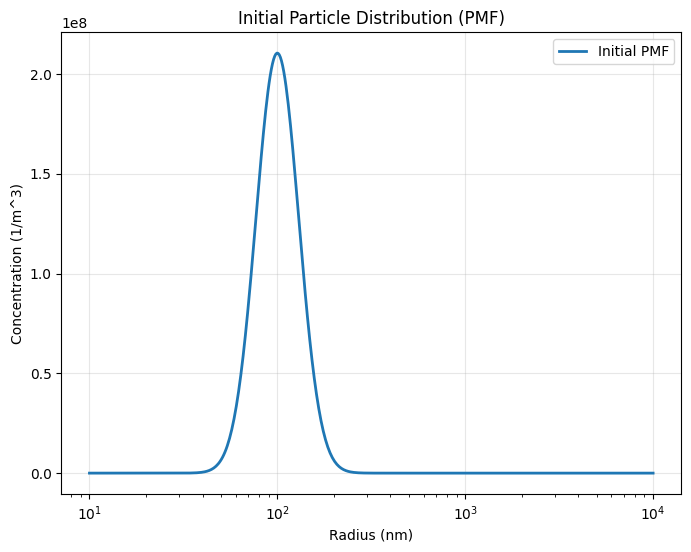

In [5]:
# Plot the initial particle distribution
fig, ax = plt.subplots(figsize=(8, 6))
ax.semilogx(
    initial_radii * 1e9,
    initial_concentration,
    label="Initial PMF",
    linewidth=2,
)
ax.set_xlabel("Radius (nm)")
ax.set_ylabel("Concentration (1/m^3)")
ax.legend()
ax.set_title("Initial Particle Distribution (PMF)")
ax.grid(alpha=0.3)
plt.show()

> **Note:** Full time evolution with bin-based representations requires
> careful handling of the distribution array dimensions. For complete
> working examples of condensation dynamics, see
> `staggered_condensation_example.ipynb` which uses particle-resolved
> representations that are designed for multi-step simulations.

## Summary

This notebook demonstrated the basic setup for condensation with:

- **Vapor Pressure Strategy**: Clausius-Clapeyron equation for glycerol
- **Gas Species**: Native `GasData` with partitioning enabled
- **Particle Distribution**: PMF (bin-based) representation
- **Condensation Strategy**: `CondensationIsothermal` for simple mass transfer
- **Runnable Process**: `MassCondensation` wraps the strategy

For complete time evolution examples with particle-resolved representations,
see `staggered_condensation_example.ipynb`.